# Numerical accuracy of a joint DES Y3 Fisher calculation

This notebook asks whether changes in numerical resolution change the
derivatives that determine the marginalized $w_0$–$w_a$ ellipse. It starts
from a full Fisher calculation at the default accuracy, reads inexpensive
checks at chosen parameter columns, and then reads full recalculations where
archives exist. NLA and TATT keep separate baselines, priors, parameter sets
and diagnostic weights.

Interpolation error can masquerade as signal: a grid that is too coarse
generates an artificial high-multipole contribution in the TATT prediction.
The configured calculation uses signed component ratios and triangle and
angular grids that the
[interpolation study](tests/studies/interpolation_validation.md) checks
against that failure. The diagnostics below test the configured numerical
calculation only. The YAML files record the input covariance, the source
preparation, the unvalidated agreement with the exact measured aperture
estimator, the scale cuts and the physical approximations, so a passed
numerical check does not reproduce either published DES analysis.

## Contents

1. [Set up the notebook](#setup)
2. [The fiducial two-point quadrature](#xi)
3. [The baselines and the follow-up plan](#baseline)
4. [What the inexpensive noise estimator measures](#noise)
5. [Baseline columns and candidate checks](#screen)
6. [Parameter steps with saved-node reuse](#steps)
7. [Full derivative recalculations](#full)
8. [Run additional checks](#run)
9. [What the evidence establishes](#interpretation)

**Model and data.** The two studies read these inputs:

| Choice | Value |
| --- | --- |
| NLA configuration | `configs/des_y3_nla_demo_fisher.yaml`, results in `chains/nla_accuracy/` |
| TATT configuration | `configs/des_y3_tatt_demo_fisher.yaml`, results in `chains/tatt_accuracy/` |
| Accuracy plan | `configs/des_y3_fisher_accuracy.yaml` |
| Joint vector | $\boldsymbol d=(\xi_+,\xi_-,\langle M_\mathrm{ap}^3\rangle)$ with a fixed covariance |
| Two-point quadrature | default $N_\ell=4096$, $N_\theta=32$, $\ell_\mathrm{max}=40000$; reference $32768/256/80000$ (`chains/xi_refinement/`) |
| Step studies | $\Delta_{\Omega_m}=0.003$ and $\Delta_h=0.005$ (`chains/nla_step_study/`, `chains/tatt_step_study/`) |
| Angular orders | $L_\mathrm{max}=M_\mathrm{max}=20$ in every planned case |
| Threads | one BLAS worker; OpenMP capped at four |

Words used throughout:

- The **Fisher matrix** $F$ is the local Gaussian information of the forecast;
  its inverse $S=F^{-1}$ is the parameter covariance, and the **FoM** (figure
  of merit) measures the inverse area of the marginalized $w_0$–$w_a$ ellipse.
- A **stencil** is the set of parameter displacements whose mean vectors enter
  one finite-difference derivative; the five-point stencil at spacing $h$ uses
  the displacements $0,\pm h,\pm 2h$.
- The **fourth difference** combines the five stencil points so that every
  smooth polynomial through cubic order cancels; what survives measures
  jitter.
- An **archive** is a saved result set (means, derivatives, metadata and
  digests) that the loaders verify before any figure reads it.
- **NLA** is the nonlinear alignment model of intrinsic alignments; **TATT**,
  tidal alignment and tidal torquing, adds quadratic tidal terms.

<a name="setup"></a>
## 1. Set up the notebook

Run from the `des_3pcf` project directory. BLAS uses one thread throughout,
OpenMP owns any parallel C work with at most four workers, and loading saved
arrays or drawing figures launches no model evaluation. The public
`threadpoolctl` API also sets already loaded BLAS libraries to one thread,
which matters when the notebook shares a reused kernel.

The plotting functions receive arrays and leave fonts to the notebook;
`cosmolike_notebook_utils` provides them to every project, and the project
wrapper checks saved-file identities and decides which results are available.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import importlib
import os
from pathlib import Path
import sys

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"

PROJECT = Path.cwd().resolve()
if not (PROJECT / "README.md").is_file():
    raise RuntimeError("Run this notebook from Cocoa/projects/des_3pcf.")
CORE = PROJECT.parents[1] / "external_modules/code/cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))

import matplotlib
from matplotlib import pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_info, threadpool_limits

blas_limit = threadpool_limits(limits=1, user_api="blas")
for pool in threadpool_info():
    if pool["user_api"] == "blas" and pool["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS pool still has more than one thread.")

from cosmolike_des_3pcf_accuracy_wrappers import AccuracyStudy, plot_xi_preflight

# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'

<a name="xi"></a>
## 2. The fiducial two-point quadrature

A small error in a mean vector can become a large derivative error after
division by a small parameter step, so the first check examines the numerical
integral behind $\xi_\pm$ independently of the later Fisher diagnostics. The
saved scan varies the number of Fourier quadrature nodes $N_\ell$, the number
of nodes that average each angular bin $N_\theta$, and the integration upper
bound $\ell_\mathrm{max}$.

The plotted quantity is

$$
D_\xi^2 =
(\boldsymbol{\xi}_{q}-\boldsymbol{\xi}_\mathrm{ref})^{\mathsf T}
C_\xi^{-1}
(\boldsymbol{\xi}_{q}-\boldsymbol{\xi}_\mathrm{ref}),
$$

where $q$ labels a numerical setting and $C_\xi$ is the two-point covariance
block. This is a covariance-weighted distance between predictions, not a fit
to observed data. The reference uses $32768$ Fourier nodes, $256$ angular
nodes and $\ell_\mathrm{max}=80000$.

The archive `chains/xi_refinement` records this scan with the `linear_midpoint`
source reconstruction and the physics tables of `chains/y3_demo_physics.npz`,
and it explains the quadrature choice. The Fisher bases below use the
measured-edge PCHIP (shape-preserving cubic) sources, so the `xi_ell_2` scan
in the plan rechecks derivatives with those inputs, and angular averaging and
the integration bound stay separate controls.

The archive records $D_\xi^2\simeq14.9$ for $256/32/40000$ and about $0.00126$
for $4096/32/40000$, the setting the Fisher bases use. The plateau reached by
raising $N_\ell$ alone is instructive: angular averaging and the finite
integration bound still leave differences. The reference has zero distance
from itself, so the logarithmic plot omits it without substituting a floor.
The scan covers the fiducial vector; displaced parameter vectors and their
derivatives need the following tests.

Fiducial quadrature check; no derivative or survey-model convergence claim.
The log plot omits 1 exact-zero reference/identical cases.


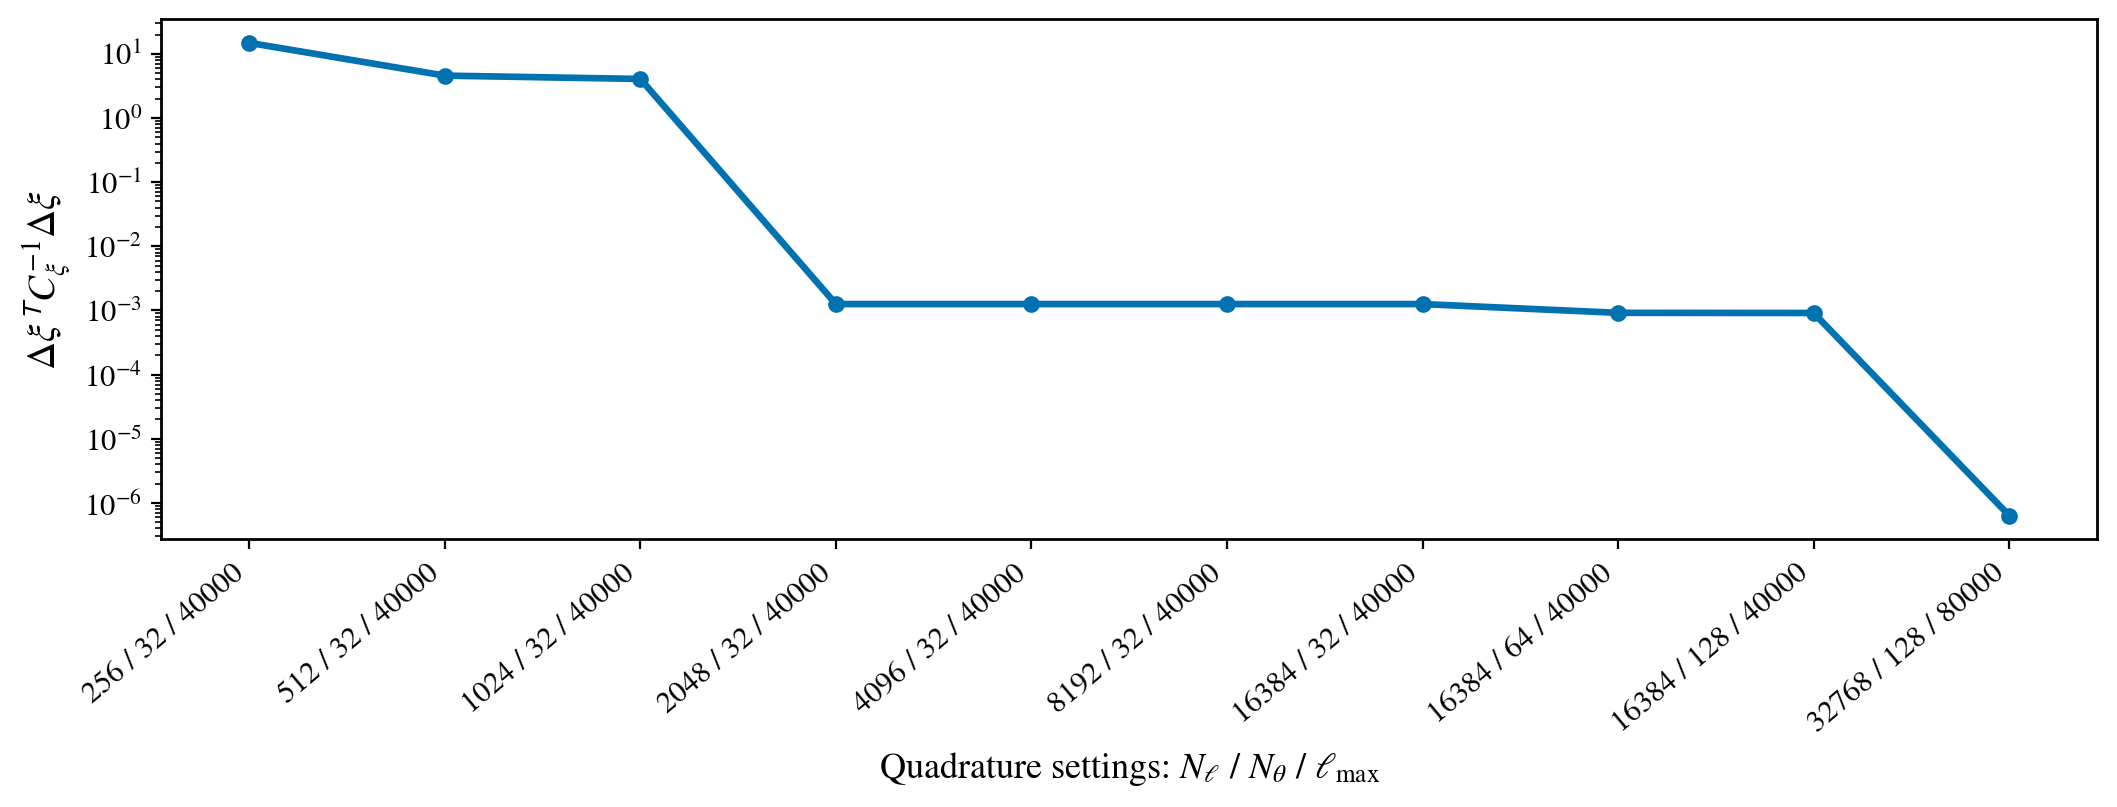

In [2]:
plot_xi_preflight(directory=PROJECT / "chains/xi_refinement");

<a name="baseline"></a>
## 3. The baselines and the follow-up plan

For the uncompressed joint vector
$\boldsymbol d=(\xi_+,\xi_-,\langle M_\mathrm{ap}^3\rangle)$, the project forms

$$
F_{\alpha\beta}
= D_\alpha^{\mathsf T}C^{-1}D_\beta
+F^\mathrm{prior}_{\alpha\beta},
\qquad
D_\alpha=\frac{\partial\boldsymbol d}{\partial p_\alpha},
$$

with the covariance $C$ held fixed and every stated Gaussian prior included
before marginalization. If $S=F^{-1}$ is the parameter covariance, the figure
of merit is

$$
\mathrm{FoM}_{w_0w_a} =
\left[\det S_{\{w_0,w_a\}}\right]^{-1/2},
$$

so a nuisance derivative can alter the dark-energy ellipse even when that
nuisance is not one of the two displayed axes.

The full baseline stores five mean vectors per parameter at spacings $h$ and
$h/2$. Several points coincide, so both derivative sets need six distinct
off-center means per parameter plus one shared fiducial mean. The cheap scan
reuses these arrays and this full Fisher matrix: only the chosen parameter
columns receive new mean evaluations at a candidate accuracy, and a status
check reads completed files without launching missing work.

In [3]:
studies = {
    "NLA": AccuracyStudy(
        configuration=PROJECT / "configs/des_y3_nla_demo_fisher.yaml",
        output=PROJECT / "chains/nla_accuracy",
        plan=PROJECT / "configs/des_y3_fisher_accuracy.yaml",
    ),
    "TATT": AccuracyStudy(
        configuration=PROJECT / "configs/des_y3_tatt_demo_fisher.yaml",
        output=PROJECT / "chains/tatt_accuracy",
        plan=PROJECT / "configs/des_y3_fisher_accuracy.yaml",
    ),
}
for label, study in studies.items():
    display(Markdown(f"### {label}\n\n" + study.summary_markdown()))

### NLA

**4 completed candidate scans.** Selected parameters: w0, wa, h, omega_m.

They cover 99.9% of the measured baseline contribution. Baseline-only parameters: sigma8, omega_b, ns, a1, eta1, m1, m2, m3, m4, dz1, dz2, dz3, dz4.

Each candidate requests 17 distinct means; the default Fisher supplies the fixed marginalization weights.

Pending planned scans: source_2, kernel_2, multipole_1p5, angular_2, fft_1p5, xi_theta_2, sampling_1p5, sampling_2, integration_2.

The omitted share describes the measured baseline only. It does not bound unknown noise at another setting. Small scores cannot exclude coherent derivative errors or common physical-model errors.

### TATT

**4 completed candidate scans.** Selected parameters: w0, wa, h, omega_m.

They cover 99.9% of the measured baseline contribution. Baseline-only parameters: sigma8, omega_b, ns, a1, eta1, a2, eta2, bta, m1, m2, m3, m4, dz1, dz2, dz3, dz4.

Each candidate requests 17 distinct means; the default Fisher supplies the fixed marginalization weights.

Pending planned scans: source_2, kernel_2, multipole_1p5, angular_2, fft_1p5, xi_theta_2, sampling_1p5, sampling_2, integration_2.

The omitted share describes the measured baseline only. It does not bound unknown noise at another setting. Small scores cannot exclude coherent derivative errors or common physical-model errors.

<a name="noise"></a>
## 4. What the inexpensive noise estimator measures

Suppose a prediction were independent of one parameter. Its true derivative
would be zero, so the data would carry no information about that parameter.
Numerical jitter can nevertheless produce a nonzero finite-difference slope,
and squaring that slope in the Fisher matrix creates apparent information that
can shrink an ellipse artificially. The estimator below measures this effect
under a stated noise model.

Write $\boldsymbol d_j=\boldsymbol d(p_\alpha+j\epsilon_\alpha)$, holding all
other parameters fixed; $\epsilon_\alpha$ is an absolute step in the
parameter's units, including for negative or zero fiducial values. The fourth
difference and the fourth-order central derivative are

$$
\boldsymbol q_\alpha
=\boldsymbol d_{-2}-4\boldsymbol d_{-1}
+6\boldsymbol d_0-4\boldsymbol d_1+\boldsymbol d_2,
\qquad
\widehat D_\alpha
=\frac{\boldsymbol d_{-2}-8\boldsymbol d_{-1}
+8\boldsymbol d_1-\boldsymbol d_2}{12\epsilon_\alpha}.
$$

The fourth difference cancels smooth polynomials through cubic order. If the
remaining error behaves as independent, equally distributed jitter at the five
points, the squared difference coefficients sum to $70$, so the shared
estimator uses

$$
\widehat\sigma_\alpha^2
=\frac{\boldsymbol q_\alpha^{\mathsf T}C^{-1}\boldsymbol q_\alpha}{70},
\qquad
a_\alpha=\frac{130}{144}
\frac{\widehat\sigma_\alpha^2}{\epsilon_\alpha^2},
$$

where $130/144$ is the squared coefficient sum of the derivative stencil. In
that noise model, $a_\alpha$ is an expected diagonal addition to parameter
information, with units of inverse parameter squared. This is the
fourth-difference noise estimator of the Fisher machinery note
(`projects/lssty1xdesi/notes/fisher_machinery/fisher_machinery.tex`).

The same note's first-order FoM response relates these additions to the
ellipse. Let $T=\{w_0,w_a\}$, let $s_\alpha^2=S_{\alpha\alpha}$, and define

$$
R_\alpha^2 =
\frac{S_{\alpha T}S_{TT}^{-1}S_{T\alpha}}{S_{\alpha\alpha}}.
$$

Then the first-order expectation is

$$
\delta\ln\mathrm{FoM}\simeq
\frac12\sum_\alpha R_\alpha^2s_\alpha^2a_\alpha.
$$

The shared helper also rescales the FoM with the exact ratio for
$F+\operatorname{diag}(a)$, without truncating at first order. Its exactness
concerns the assumed diagonal-noise model; it does not make that model an
exact description of the numerical error.

This distinction drives the follow-up tests. A smooth fourth derivative can
enter $\boldsymbol q_\alpha$ without being numerical noise; a coherent error
proportional to the parameter displacement can change $\widehat D_\alpha$
while canceling from $\boldsymbol q_\alpha$; correlations between stencil
points or between parameter columns invalidate the independent-jitter
coefficients; and the $h$ and $h/2$ checks share points, so they are not
independent measurements to average. Actual derivative changes and full
recalculations stay necessary.

<a name="screen"></a>
## 5. Baseline columns and candidate checks

The first figure shows each parameter's measured contribution
$R_\alpha^2s_\alpha^2a_\alpha$ as a percentage of their sum at default
accuracy. The scan always includes the two FoM parameters and then adds the
columns with the largest measured contributions, up to the plan's cap. The
printed coverage is the achieved baseline share, which can fall below the
requested $95\%$, and a small correlation weight gives no bound on an omitted
column's unknown numerical noise.

The next figure compares two diagnostics. The blue curve uses the shared
diagonal-noise estimate with fixed baseline weights, normalized by the
estimate from the same baseline columns: a diagnostic of expected information
from jitter, not a candidate-to-baseline FoM prediction. The orange curve
replaces the chosen derivative columns by their actually calculated candidate
values and leaves the other columns at baseline, which detects coherent
changes the fourth difference misses while remaining a partial replacement
rather than a full refined Fisher matrix.

A partial replacement also mixes derivatives from two numerical grids.
Nuisance directions can compensate when all columns refine together, and the
mixed matrix can miss that compensation, so a large orange displacement
requests a full check rather than predicting its outcome.

All differences appear as $100(r-1)$ percent; a zero reference line means
agreement with the fixed baseline in the stated diagnostic. Missing or
rank-unresolved results stay gaps, and the notebook infers no acceptance
threshold.

`multipole_1p5` refines the interpolation tables in Fourier size and shape
angle. It does not raise the kept angular orders: every planned case keeps
$L_\mathrm{max}=M_\mathrm{max}=20$, and convergence in those orders needs a
separate truncation study.

### NLA: measured baseline contributions

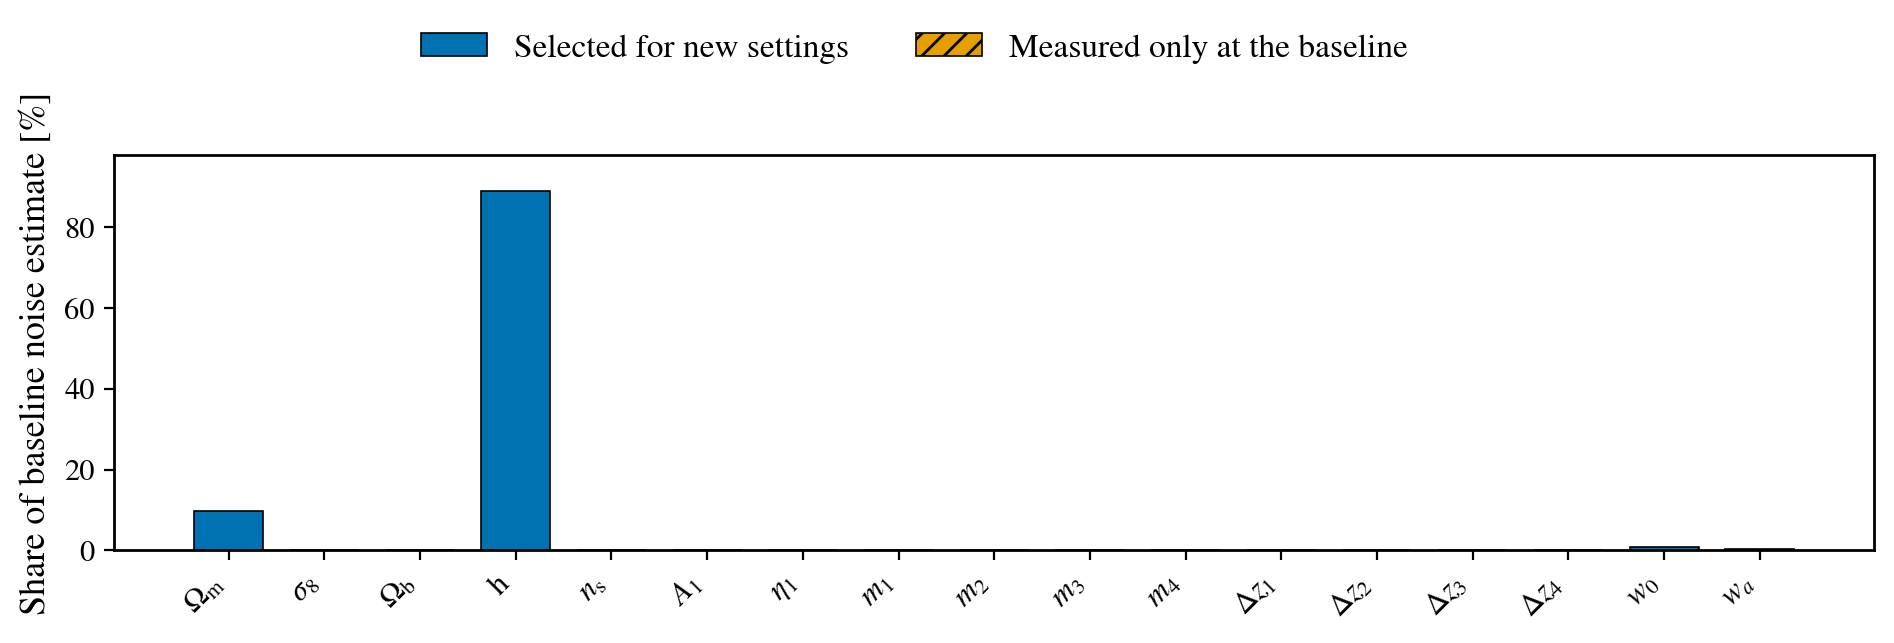

In [4]:
display(Markdown("### NLA: measured baseline contributions"))
studies["NLA"].plot_noise_contributions();

### NLA: selected-column accuracy checks

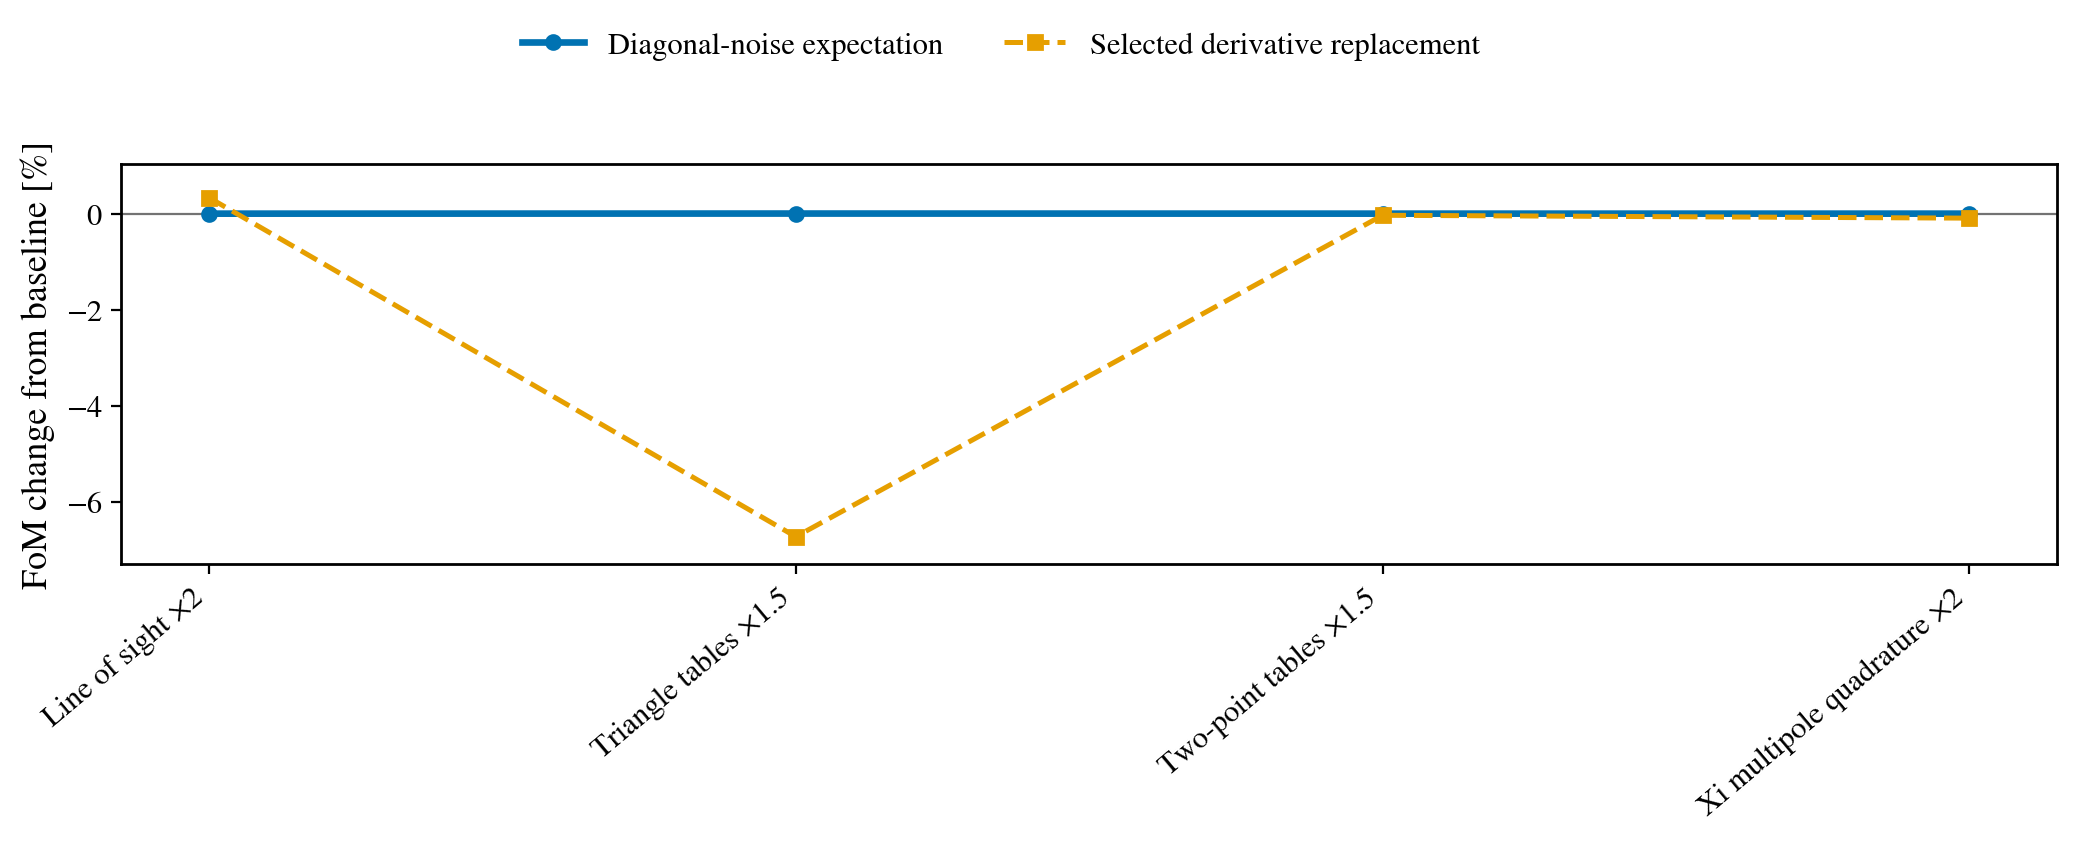

In [5]:
display(Markdown("### NLA: selected-column accuracy checks"))
studies["NLA"].plot_accuracy_screen();

### TATT: measured baseline contributions

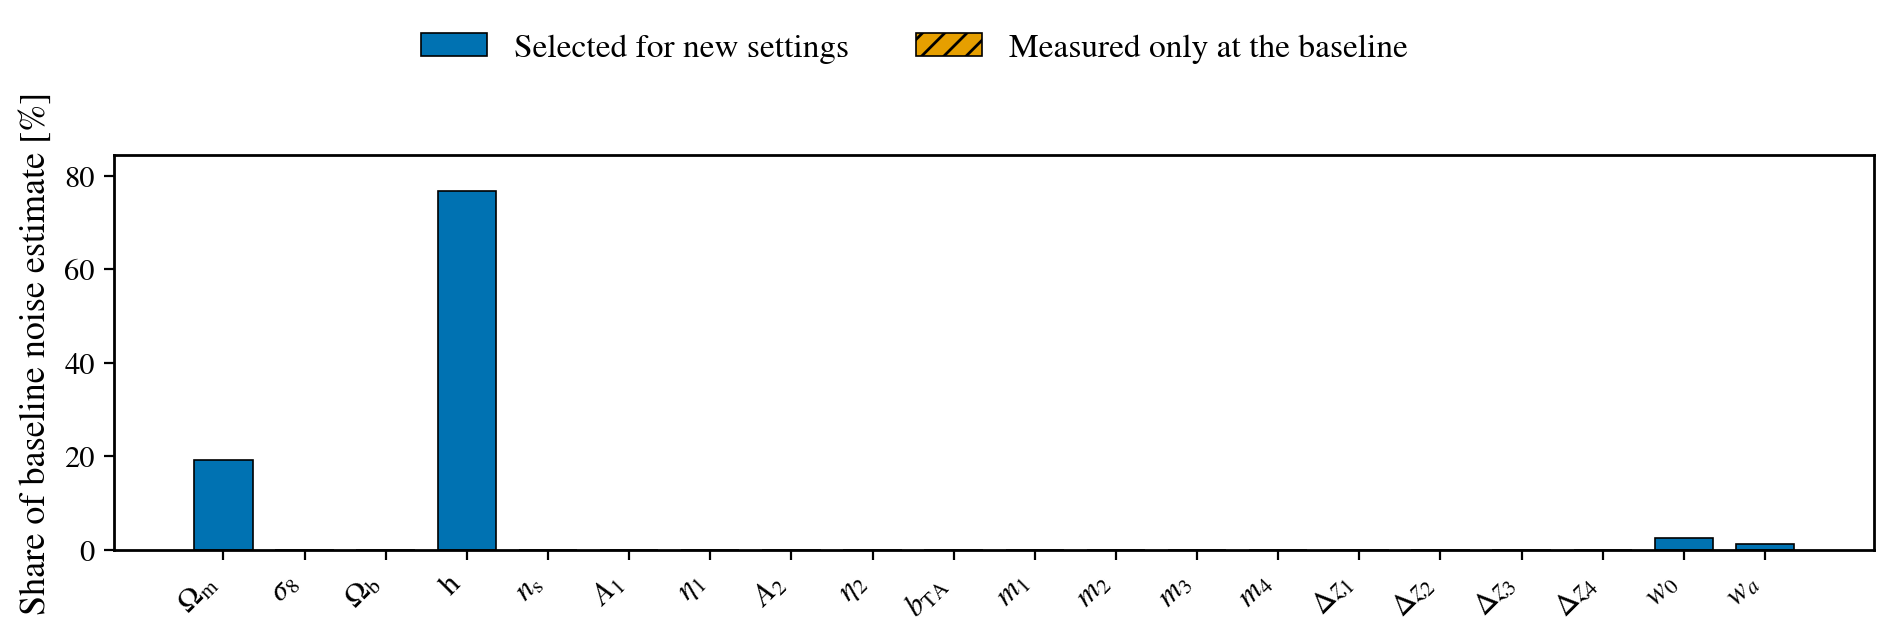

In [6]:
display(Markdown("### TATT: measured baseline contributions"))
studies["TATT"].plot_noise_contributions();

### TATT: selected-column accuracy checks

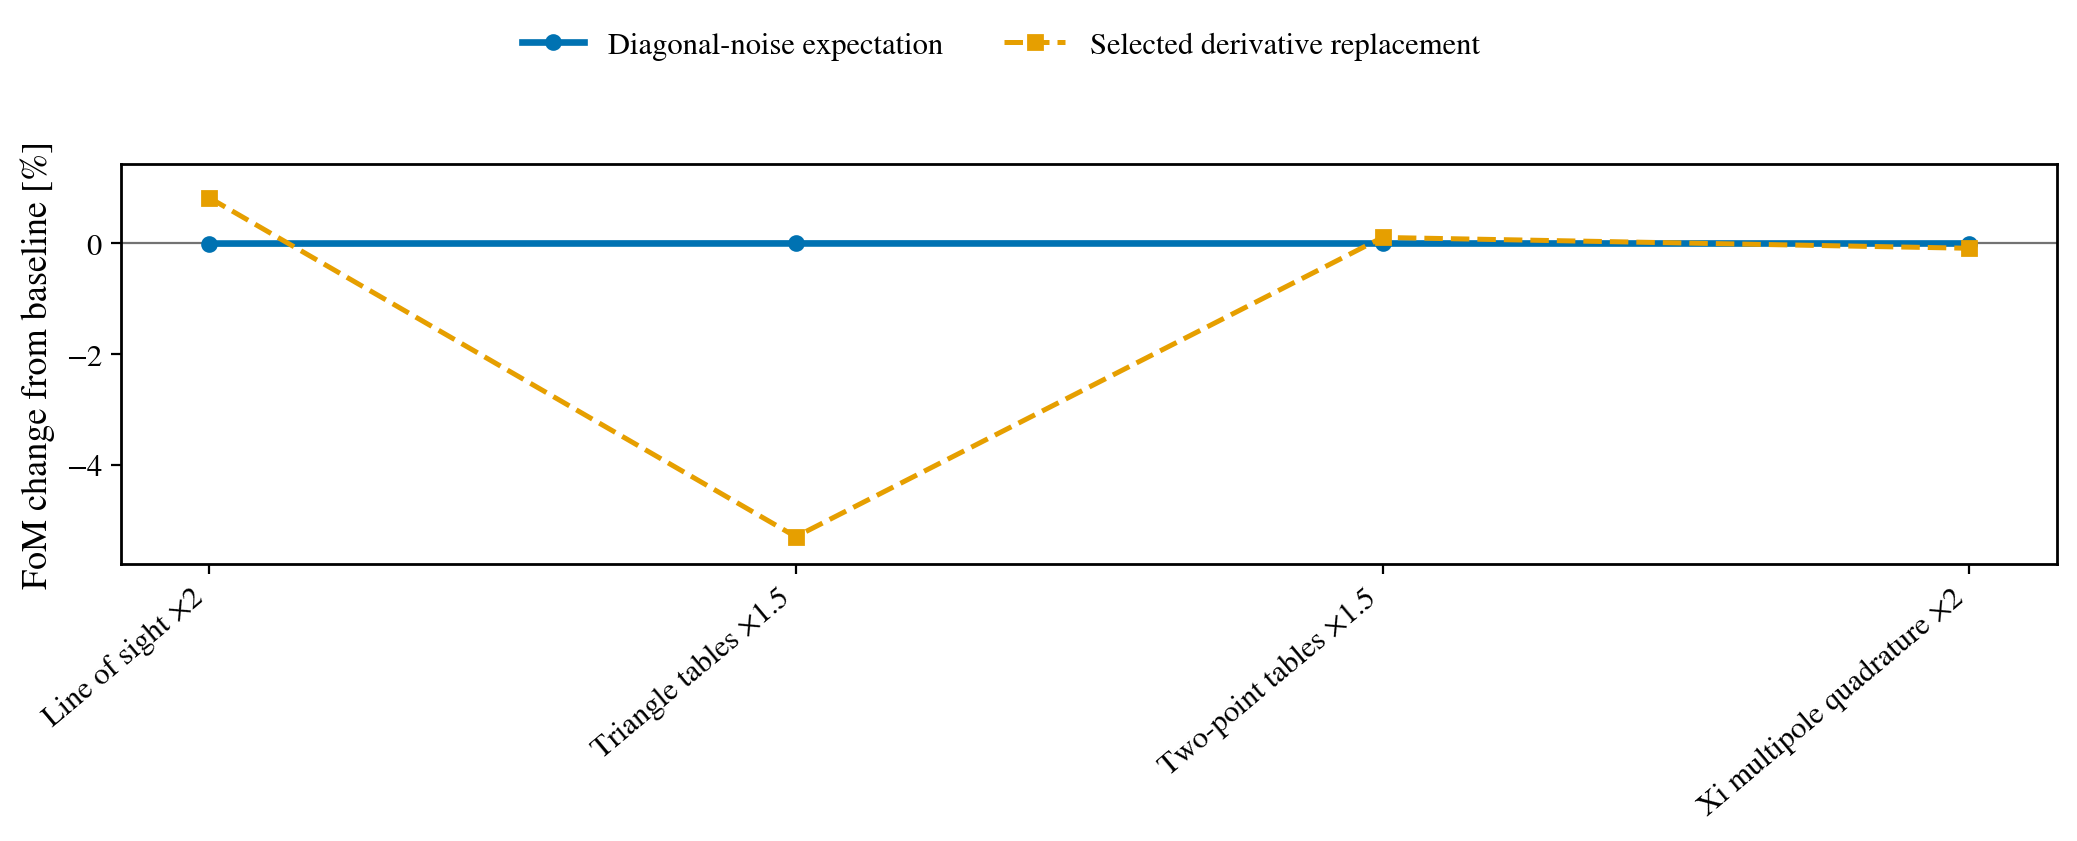

In [7]:
display(Markdown("### TATT: selected-column accuracy checks"))
studies["TATT"].plot_accuracy_screen();

<a name="steps"></a>
## 6. Parameter steps with saved-node reuse

Write $\Delta$ for each parameter's original YAML displacement; this study
uses $\Delta_{\Omega_m}=0.003$ and $\Delta_h=0.005$, where the subscript $h$
names the physical Hubble parameter. The completed default Fisher already
contains the center and the displacements $\pm\Delta/2$, $\pm\Delta$ and
$\pm2\Delta$, so only $\pm\Delta/4$ and $\pm4\Delta$ are missing: eight
additional predictions give both smaller and larger stencils for the two
chosen columns without recalculating the expensive full derivative base.

The plots compare spacings $\Delta/4$, $\Delta/2$, $\Delta$ and $2\Delta$.
Blue is the shared diagonal-noise estimate divided by its value for these same
two columns at $\Delta/2$; orange replaces their calculated derivatives in the
full $\Delta/2$ Fisher while all other columns, priors and covariance stay
fixed. Both curves diagnose the stated subset, and a favorable result does not
establish accuracy for omitted columns or another integration grid.

The loader checks the step archive against its baseline and numerical metadata
and launches no missing calculation. The
[study record](tests/studies/fisher_accuracy_validation.md) contains the
commands, the numerical findings, and the independent matrix checks explaining
why a small derivative change can move a marginalized FoM.

### NLA: selected cosmological step checks

Selected parameter columns: omega_m, h
New mean evaluations: 8
Both curves concern this selected subset; neither is a full new Fisher.
h4 absolute steps: omega_m=0.00075, h=0.00125
h2 absolute steps: omega_m=0.0015, h=0.0025
h absolute steps: omega_m=0.003, h=0.005
two_h absolute steps: omega_m=0.006, h=0.01


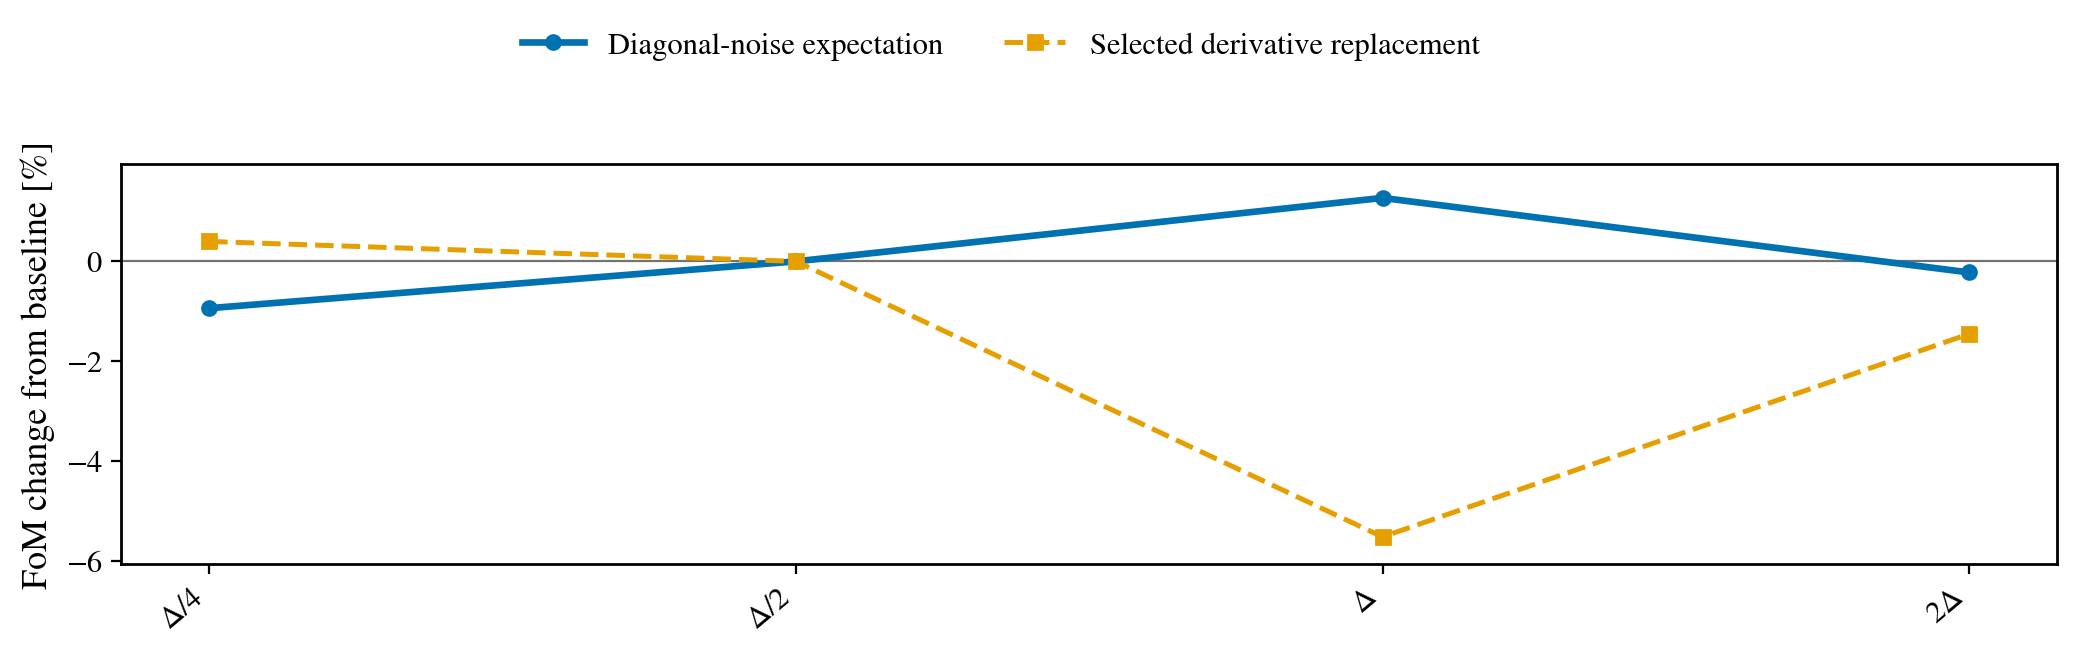

In [8]:
display(Markdown("### NLA: selected cosmological step checks"))
studies["NLA"].plot_step_study(directory=PROJECT / "chains/nla_step_study");


### TATT: selected cosmological step checks

Selected parameter columns: omega_m, h
New mean evaluations: 8
Both curves concern this selected subset; neither is a full new Fisher.
h4 absolute steps: omega_m=0.00075, h=0.00125
h2 absolute steps: omega_m=0.0015, h=0.0025
h absolute steps: omega_m=0.003, h=0.005
two_h absolute steps: omega_m=0.006, h=0.01


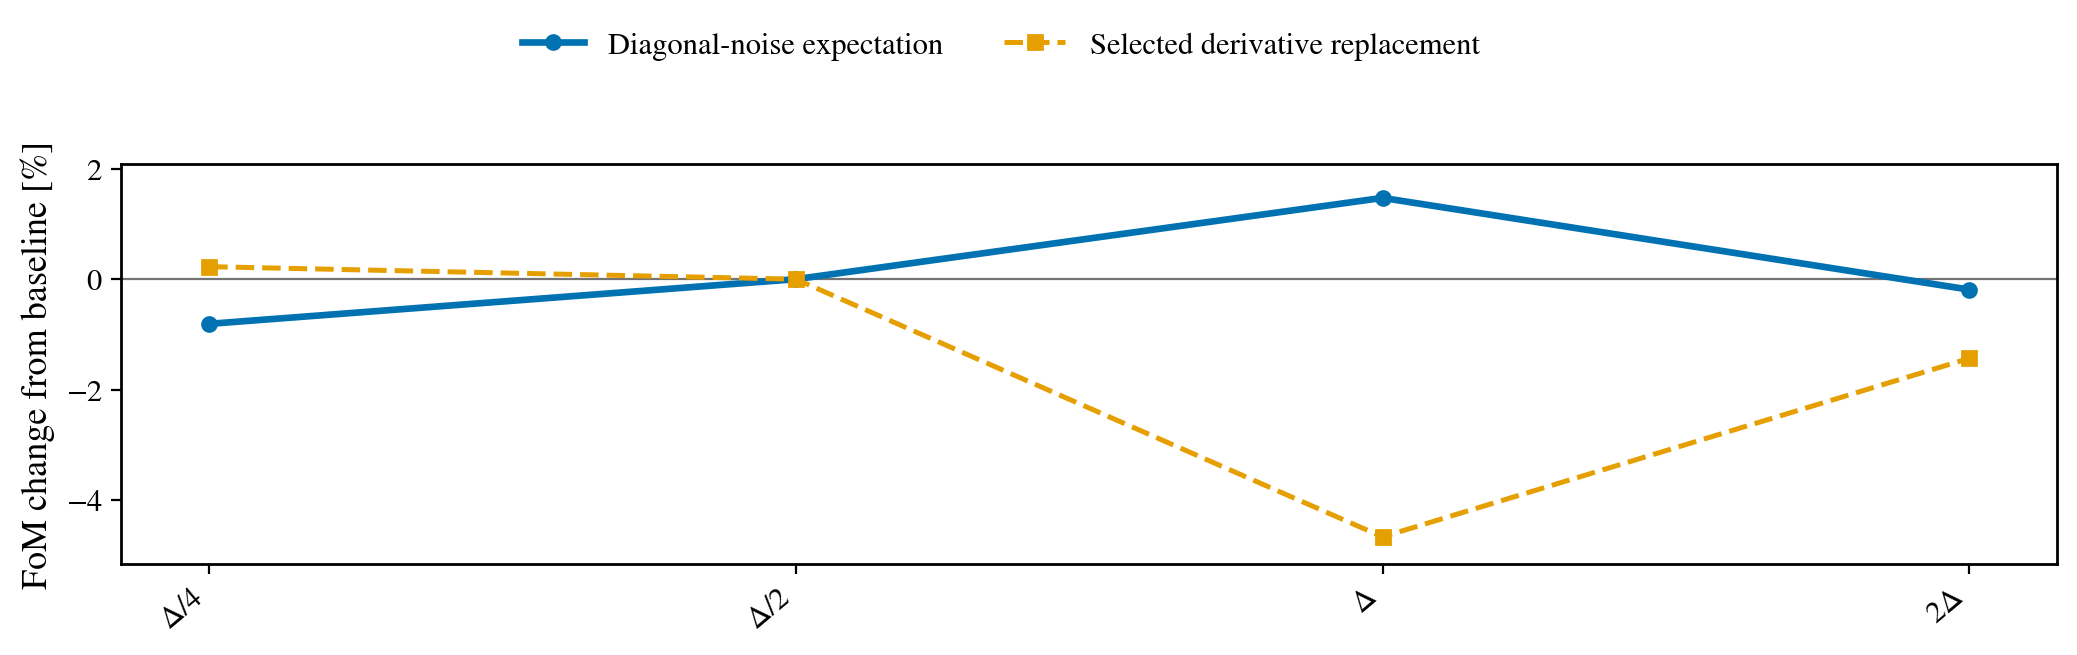

In [9]:
display(Markdown("### TATT: selected cosmological step checks"))
studies["TATT"].plot_step_study(directory=PROJECT / "chains/tatt_step_study");


<a name="full"></a>
## 7. Full derivative recalculations

These figures recalculate the FoM from every derivative column in each
available full archive. The $h$ and $h/2$ results use the same
default-accuracy FoM denominator chosen by the scan: their separation tests
parameter-step sensitivity, while changes between numerical settings test
integration and interpolation sensitivity. A matrix that fails the project's
rank test yields no parameter covariance from a pseudoinverse.

The loader checks the configuration digest, parameter order, full data-row
order, fixed covariance and archived physical-input and code identities before
combining files, and only completed full archives enter the figure. Candidate
scans without a full recalculation appear as pending; if only the baseline
appears, the figure establishes no completed accuracy refinement, even when
the cheap diagnostic was small. These numerical FoMs are diagnostics, not
accepted survey forecasts.

The figures compare archived identities with one another; an explicit new full
check verifies the current input and code files before launching, so a changed
implementation cannot masquerade as a resolution-only comparison.

The completed triangle-table refinement illustrates the difference between a
chosen-column diagnostic and a full calculation. At the smaller derivative
step, the full NLA FoM changes by **+0.170%** and the full TATT FoM by
**−0.055%**, while the four-column substitutions change them by −6.72% and
−5.30%: every shared stencil prediction agrees bit for bit, and the other
nuisance derivatives compensate when they refine together. The refined
calculations still differ by 6.08% and 5.64% between the two parameter steps,
so this comparison supports the triangle resolution while leaving step
sensitivity and angular truncation to separate checks.

### NLA: available full derivative recalculations

Full recalculations pending: chi_2, core_2pt_1p5, xi_ell_2


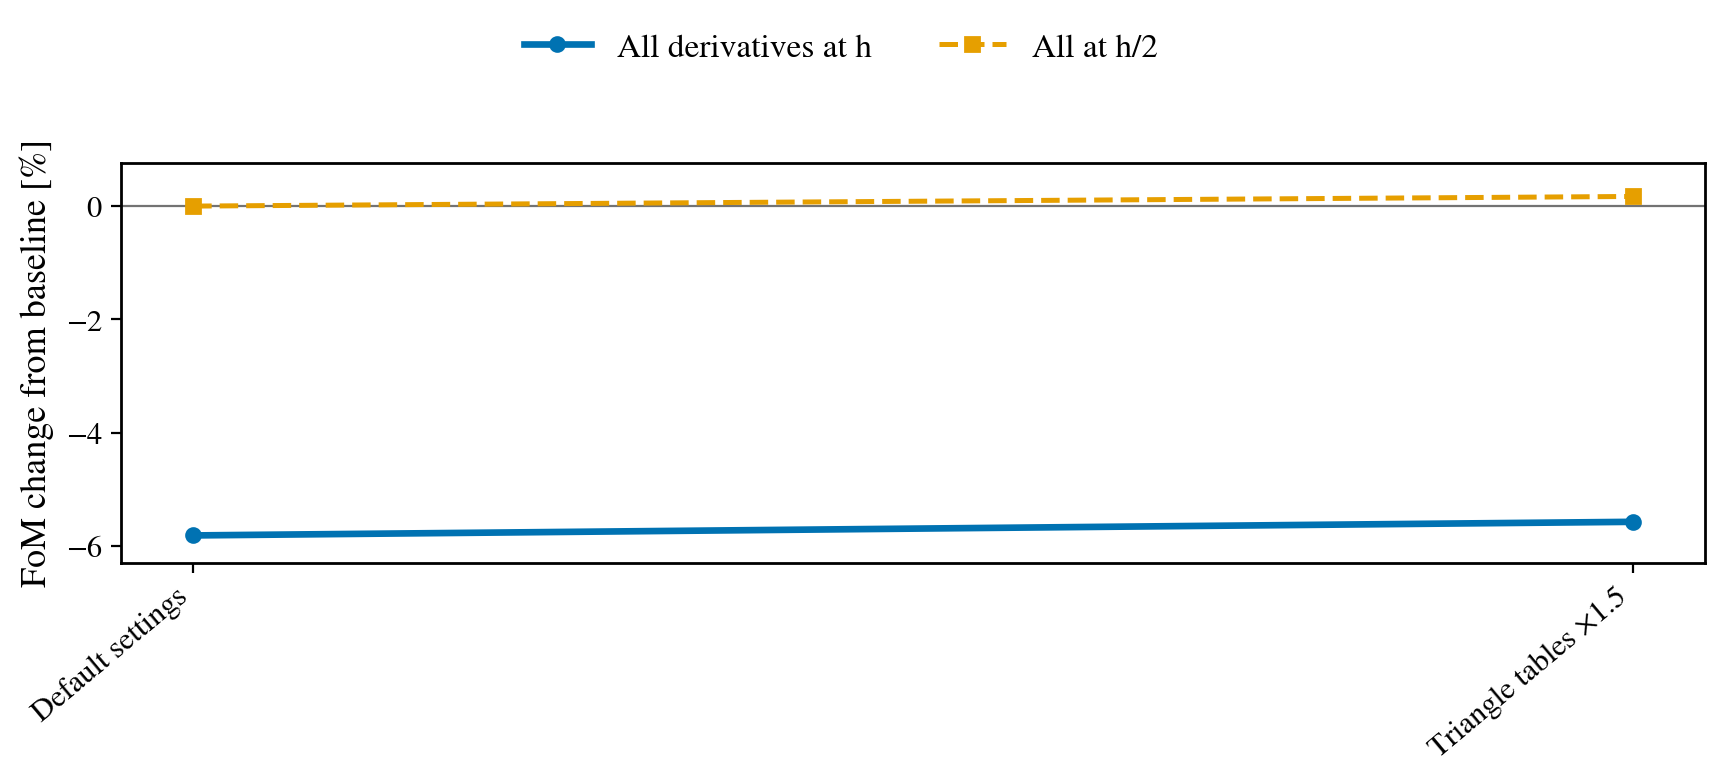

In [10]:
display(Markdown("### NLA: available full derivative recalculations"))
studies["NLA"].plot_full_checks();

### TATT: available full derivative recalculations

Full recalculations pending: chi_2, core_2pt_1p5, xi_ell_2


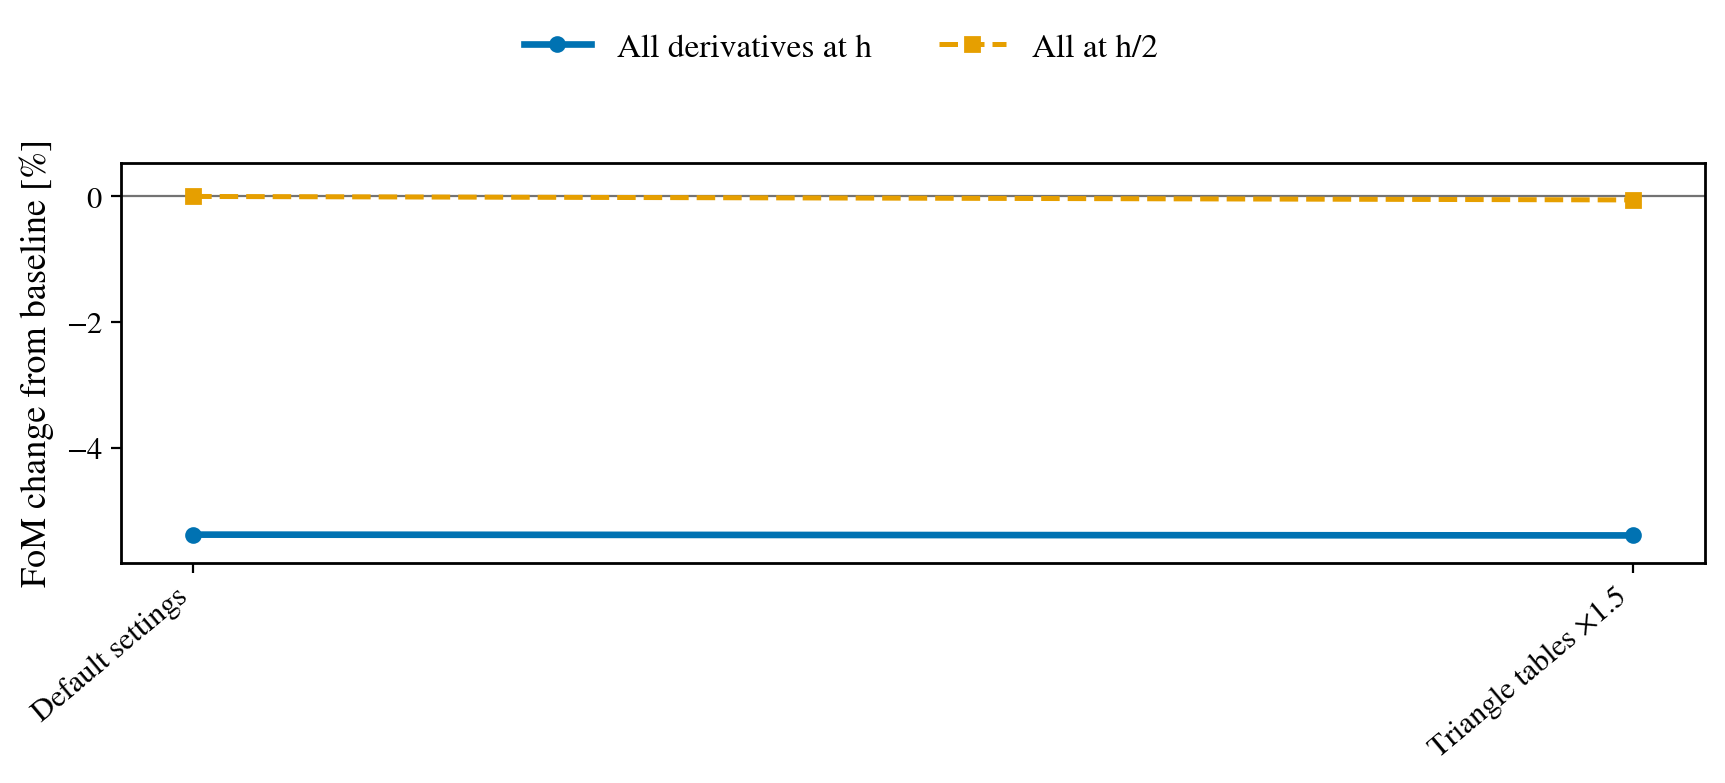

In [11]:
display(Markdown("### TATT: available full derivative recalculations"))
studies["TATT"].plot_full_checks();

### The full smaller-step archives

The figures above compare $h$ and $h/2$. The accuracy record also names a full
$h/4$ archive on each triangle-refined grid. The $h/4$ stencil reuses the
saved outer points, so each parameter needs only two inner points; four
verified points from the two-column study reduce the fresh work to **30 NLA
means and 36 TATT means**, and the driver reconstructs every original $h/2$
derivative bit for bit before accepting the new matrix.

| Model | Full triangle FoM at h/2 | Full triangle FoM at h/4 | Change |
|---|---:|---:|---:|
| NLA | 0.19149956 | 0.18988308 | −0.844% |
| TATT | 0.14396744 | 0.14302771 | −0.653% |

These all-column comparisons keep rows, covariance and priors unchanged. They
reduce the 6.08% and 5.64% step disagreements of the $h$ versus $h/2$
comparison; they do not establish an exact derivative or an accuracy
tolerance. With dark energy fixed and all other parameters marginalized, the
joint/xi matter-density–$S_8$ FoM gains become 2.16319 for NLA and 2.94268
for TATT, changes of +0.329% and −0.0759% from their refined $h/2$ values.

The earlier plots keep their default $h$ and $h/2$ bases; this table reads the
$h/4$ archives. The
[accuracy record](tests/studies/fisher_accuracy_validation.md) gives the
complete settings, saved-result paths and commands, and the
[smaller-step driver](tests/studies/full_smaller_step_study.py) verifies
identities and receipts before reusing any point. Angular refinement of
derivatives, integration limits, external power-table accuracy and the
physical assumptions stay separate tests.

<a name="run"></a>
## 8. Run additional checks

The methods below launch real calculations in separate processes with BLAS at
one thread and at most four OpenMP workers; run them only when the machine is
available. They appear as explicit commands rather than a Boolean flag, so an
apparently executed notebook cannot quietly skip the calculation.

A first pass can isolate the two-point tables, Fourier quadrature, triangle
interpolation and line-of-sight integration:

```python
studies["NLA"].run_scan(
    only=[
        "core_2pt_1p5",
        "xi_ell_2",
        "triangle_1p5",
        "chi_2",
    ],
)
```

The runner keeps existing matching cases, and every uncomputed candidate stays
listed as pending. To complete all planned scans after the baseline exists:

```python
studies["TATT"].run_scan()
```

Run the NLA scan separately:

```python
studies["NLA"].run_scan()
```

To calculate one chosen candidate, use its exact plan name; for example, once
the saved `chi_2` scan exists:

```python
studies["TATT"].run_full_check(case="chi_2")
```

A full check evaluates every derivative at both step lengths through the
ordinary Fisher driver. Re-run the loading and plotting cells afterward: they
reread the files without a kernel restart, and existing outputs stay
untouched. The printed command below also works outside the notebook.

In [12]:
for label, study in studies.items():
    print(label + ":")
    print(study.scan_command())

NLA:
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/bin/python -B /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/scripts/run_fisher_accuracy.py /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/configs/des_y3_nla_demo_fisher.yaml --plan /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/configs/des_y3_fisher_accuracy.yaml --output /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/nla_accuracy
TATT:
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/bin/python -B /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/scripts/run_fisher_accuracy.py /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/configs/des_y3_tatt_demo_fisher.yaml --plan /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/

<a name="interpretation"></a>
## 9. What the evidence establishes

A stable noise estimate helps decide where to spend further calculations; a
stable full FoM across numerical settings and parameter steps is stronger
evidence for the same numerical problem. Neither test changes the physical
problem being solved. Keep the following separate:

- **Sampling and quadrature:** the number of line-of-sight, interpolation,
  transform, multipole and angular nodes. The scan changes their resolution
  while keeping the model fixed.
- **Support and estimator:** integration bounds, finite side-angle-side (SAS)
  triangle support, bin weighting, angular averaging and the aperture
  definition. More nodes at fixed bounds do not test these choices.
- **Spin and ordered legs:** Fourier phases, the natural-component convention
  and the ordered TATT source weights. A common convention error can survive
  every resolution test.
- **Physical assumptions:** the IA power prescription, the baryonic response,
  the effective-growth treatment of massive neutrinos, the scale cuts and the
  covariance-model consistency. These need physical comparisons or separate
  model variations.
- **Forecast design:** priors, the fitted parameter set, the fixed-covariance
  assumption and the absence of compression. The saved configuration specifies
  them, and they must not change unnoticed during an accuracy comparison.

The implementation uses the shared Fisher diagnostic in
`external_modules/code/cosmolike_core/cosmolike_notebook_utils/fisher.py`,
with project adapters in [fisher_accuracy.py](../../external_modules/code/cosmolike_core/cosmolike_notebook_utils/fisher.py);
the fourth-difference noise estimator and the first-order FoM response come
from the Fisher machinery note named in section 4. The scientific scope of the
DES configurations is in [README.md](README.md#estimator) and the YAML
notes. The separate
[angular-order study](tests/studies/angular_order_results.md) holds five
completed fiducial comparisons per IA model, isolating Legendre order, Fourier
order, angular sampling and coupling interpolation; those mean-vector
distances supplement the derivative plots above without replacing angular
refinement of the derivatives.